# Principal Component Analysis (PCA) on Iris Dataset
---

## Loading the Iris dataset

The Iris dataset is directly available as part of scikit-learn. It can be loaded
using the :func:`~sklearn.datasets.load_iris` function. With the default parameters,
a :class:`~sklearn.utils.Bunch` object is returned, containing the data, the
target values, the feature names, and the target names.



In [1]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
print(iris.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


## Plot of pairs of features of the Iris dataset

Let's first plot the pairs of features of the Iris dataset.



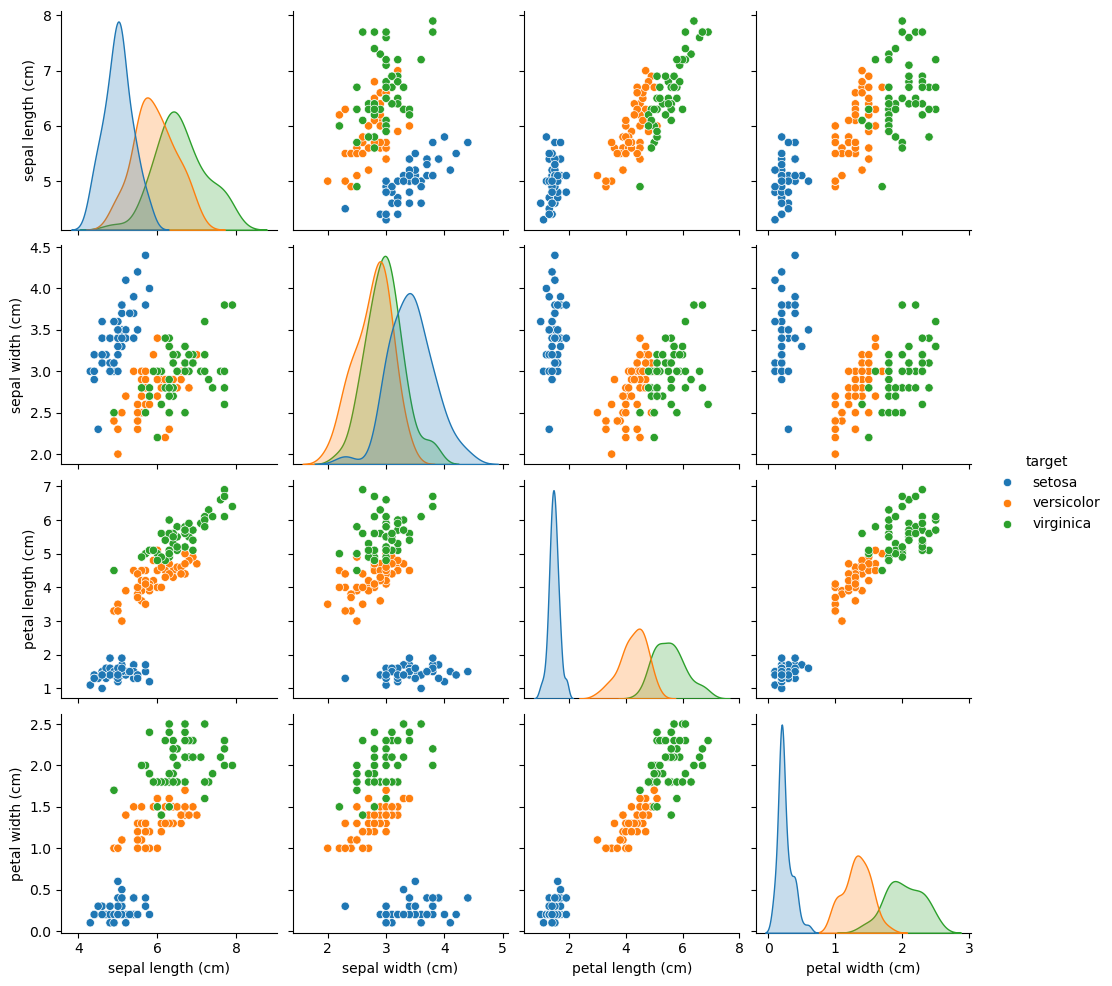

In [2]:
import seaborn as sns

# Rename classes using the iris target names
iris.frame["target"] = iris.target_names[iris.target]
_ = sns.pairplot(iris.frame, hue="target")

* Se observa en la variable **petal length** la presencia de 2 clusters (celeste por un lado y por otro naranja+verde)

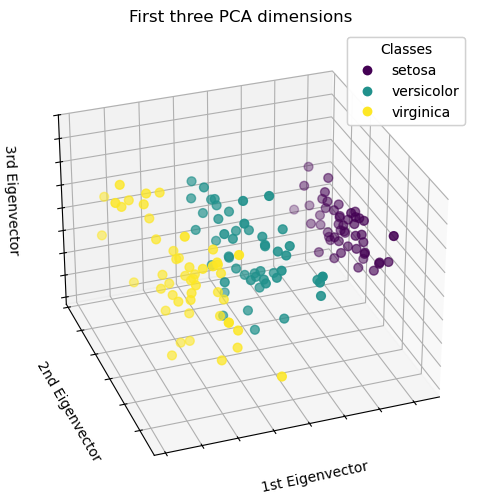

In [3]:
import matplotlib.pyplot as plt

# unused but required import for doing 3d projections with matplotlib < 3.2
import mpl_toolkits.mplot3d  # noqa: F401

from sklearn.decomposition import PCA

fig = plt.figure(1, figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d", elev=-150, azim=110)

X_reduced = PCA(n_components=3).fit_transform(iris.data)
scatter = ax.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    X_reduced[:, 2],
    c=iris.target,
    s=40,
)

ax.set(
    title="First three PCA dimensions",
    xlabel="1st Eigenvector",
    ylabel="2nd Eigenvector",
    zlabel="3rd Eigenvector",
)
ax.xaxis.set_ticklabels([])
ax.yaxis.set_ticklabels([])
ax.zaxis.set_ticklabels([])

# Add a legend
legend1 = ax.legend(
    scatter.legend_elements()[0],
    iris.target_names.tolist(),
    loc="upper right",
    title="Classes",
)
ax.add_artist(legend1)

plt.show()

PCA will create 3 new features that are a linear combination of the 4 original
features. In addition, this transformation maximizes the variance. With this
transformation, we see that we can identify each species using only the first feature
(i.e., first eigenvector).



In [4]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# 1. Datos
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)

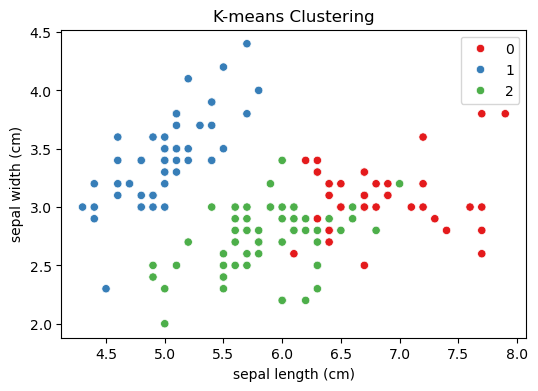

In [6]:
# 2. K-means
kmeans = KMeans(n_clusters=3, random_state=123)
kmeans_labels = kmeans.fit_predict(df)

plt.figure(figsize=(6,4))
sns.scatterplot(x=df.iloc[:,0], y=df.iloc[:,1], hue=kmeans_labels, palette="Set1")
plt.title("K-means Clustering")
plt.show()

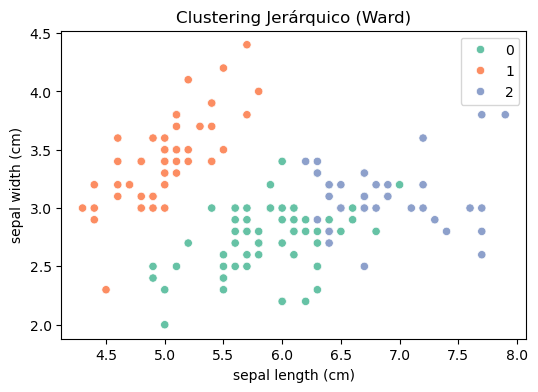

In [7]:
# 3. Clustering jerárquico (Ward)
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
hc_labels = hc.fit_predict(df)

plt.figure(figsize=(6,4))
sns.scatterplot(x=df.iloc[:,0], y=df.iloc[:,1], hue=hc_labels, palette="Set2")
plt.title("Clustering Jerárquico (Ward)")
plt.show()

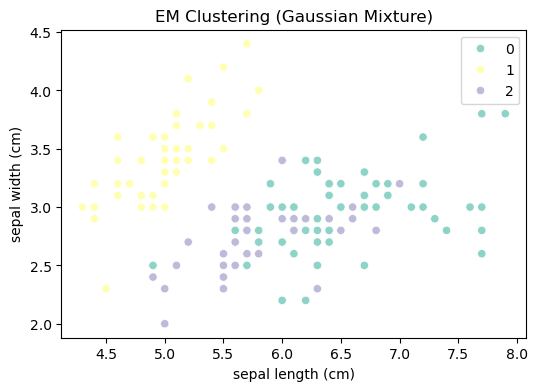

In [8]:
# 4. EM (Gaussian Mixture Model)
gmm = GaussianMixture(n_components=3, random_state=123)
gmm_labels = gmm.fit_predict(df)

plt.figure(figsize=(6,4))
sns.scatterplot(x=df.iloc[:,0], y=df.iloc[:,1], hue=gmm_labels, palette="Set3")
plt.title("EM Clustering (Gaussian Mixture)")
plt.show()

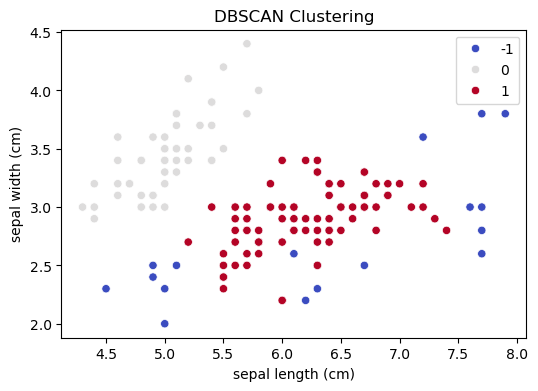

In [9]:
# 5. DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(df)

plt.figure(figsize=(6,4))
sns.scatterplot(x=df.iloc[:,0], y=df.iloc[:,1], hue=dbscan_labels, palette="coolwarm")
plt.title("DBSCAN Clustering")
plt.show()

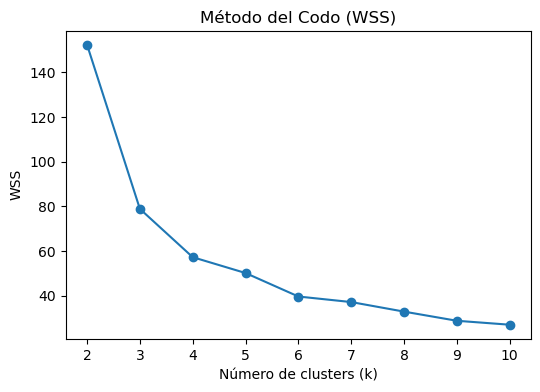

In [10]:
# 6. Método del codo (WSS)
wss = []
K = range(2,11)
for k in K:
    km = KMeans(n_clusters=k, random_state=123).fit(df)
    wss.append(km.inertia_)

plt.figure(figsize=(6,4))
plt.plot(K, wss, marker='o')
plt.title("Método del Codo (WSS)")
plt.xlabel("Número de clusters (k)")
plt.ylabel("WSS")
plt.show()

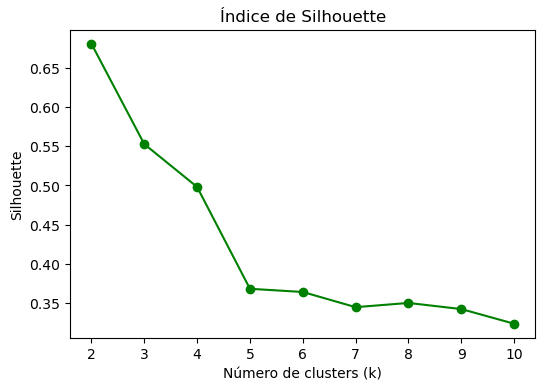

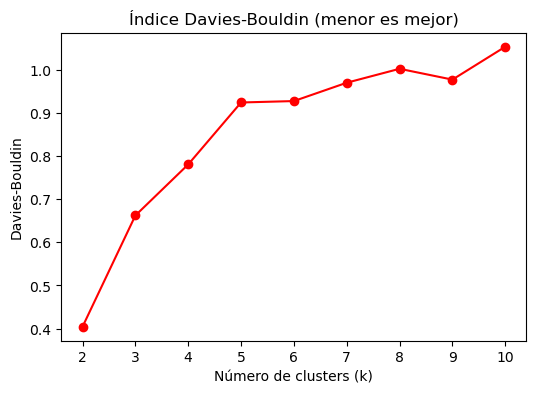

In [11]:
# 7. Silhouette y Davies-Bouldin
silhouette_scores = []
db_scores = []
for k in K:
    km = KMeans(n_clusters=k, random_state=123).fit(df)
    labels = km.labels_
    silhouette_scores.append(silhouette_score(df, labels))
    db_scores.append(davies_bouldin_score(df, labels))

# Gráfico Silhouette
plt.figure(figsize=(6,4))
plt.plot(K, silhouette_scores, marker='o', color='green')
plt.title("Índice de Silhouette")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette")
plt.show()

# Gráfico Davies-Bouldin
plt.figure(figsize=(6,4))
plt.plot(K, db_scores, marker='o', color='red')
plt.title("Índice Davies-Bouldin (menor es mejor)")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Davies-Bouldin")
plt.show()